In [23]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import pro_ang1


In [24]:
# Experiment parameters
max_order_slep = 35
Nsamples = np.logspace(1, 4, 10).astype(int)
Ntest = 1000
Para_slep = [10]
total_runs = 20
cVal = [3, 3.5, 4, 4.5, 5]


In [25]:
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]."""
    return rng.uniform(-1, 1, size=int(n_samples))

In [26]:
#This is the function that we approximate
def funct(x):
    # t is the variable
    g = np.exp(-0.5*(x)**2)


    return g

In [27]:
def NorSlep(j, c):
    """Compute the approximate L2 normalization of a Slepian function."""
    theta = np.linspace(-1, 1, 200)
    pswf_values = pro_ang1(0, j, c, theta)[0]

    # Exclude the two endpoint samples
    pswf_values = pswf_values[1:-1]
    theta_interior = theta[1:-1]

    # Trapezoidal approximation of the normalized L2 norm
    l2_norm = np.sqrt(
        0.5 * np.trapezoid(np.abs(pswf_values)**2, x=theta_interior)
    )

    return l2_norm


In [28]:

# Evaluate the normalized Slepian function of degree j
# and bandwidth c at x.

def PSWF(x, j, c):
    pswf_values = pro_ang1(0, j, c, x)[0]
    l2_norm = NorSlep(j, c)

    return pswf_values / l2_norm


In [29]:

# Construct the least-squares design matrix

def Matrix(samp, ordens, c):
    return np.column_stack([
        PSWF(samp, j, c)
        for j in range(ordens)
    ])


In [30]:

# Run the least-squares experiment for each bandwidth

max_order = Para_slep[-1]

MSE_slep = np.zeros(
    (len(cVal), len(Para_slep), len(Nsamples), total_runs)
)

start_time = time.time()
total_iterations = len(cVal) * len(Para_slep) * len(Nsamples) * total_runs
counter = 0

for ic, c in enumerate(cVal):

    # Generate training and test data for each repetition
    for run in range(total_runs):
        SamSet = samps(Nsamples[-1])
        y_train = funct(SamSet)

        TestSet = samps(Ntest)
        y_test = funct(TestSet)

        # Construct the Slepian matrices once for this repetition
        A = Matrix(SamSet, max_order, c)
        A_test = Matrix(TestSet, max_order, c)

        for orde, order in enumerate(Para_slep):
            for k, n_samples in enumerate(Nsamples):

                A_s = A[:n_samples, :order]
                y_s = y_train[:n_samples]
                A_test_s = A_test[:, :order]

                # Least-squares approximation
                coeffs = np.linalg.lstsq(A_s, y_s, rcond=None)[0]
                y_pred = A_test_s @ coeffs

                # Root-mean-square test error
                error = np.linalg.norm(y_pred - y_test) / np.sqrt(Ntest)
                MSE_slep[ic, orde, k, run] = error

                counter += 1
                elapsed = time.time() - start_time
                remaining = (total_iterations - counter) * elapsed / counter

                print(
                    f"c={c}, error={error:.6g}, "
                    f"progress={100 * counter / total_iterations:.2f}%, "
                    f"estimated remaining={remaining:.1f} seconds"
                )


c=3, error=8.65541e-07, progress=0.10%, estimated remaining=1781.9 seconds
c=3, error=9.32591e-07, progress=0.20%, estimated remaining=890.1 seconds
c=3, error=1.97686e-07, progress=0.30%, estimated remaining=592.9 seconds
c=3, error=2.01049e-08, progress=0.40%, estimated remaining=444.3 seconds
c=3, error=1.83983e-08, progress=0.50%, estimated remaining=355.1 seconds
c=3, error=1.78873e-08, progress=0.60%, estimated remaining=295.6 seconds
c=3, error=1.82305e-08, progress=0.70%, estimated remaining=253.1 seconds
c=3, error=1.79141e-08, progress=0.80%, estimated remaining=221.3 seconds
c=3, error=1.77619e-08, progress=0.90%, estimated remaining=196.5 seconds
c=3, error=1.77896e-08, progress=1.00%, estimated remaining=176.7 seconds
c=3, error=1.17132e-05, progress=1.10%, estimated remaining=322.7 seconds
c=3, error=9.46205e-06, progress=1.20%, estimated remaining=295.5 seconds
c=3, error=3.06496e-08, progress=1.30%, estimated remaining=272.5 seconds
c=3, error=2.17128e-08, progress=1.40

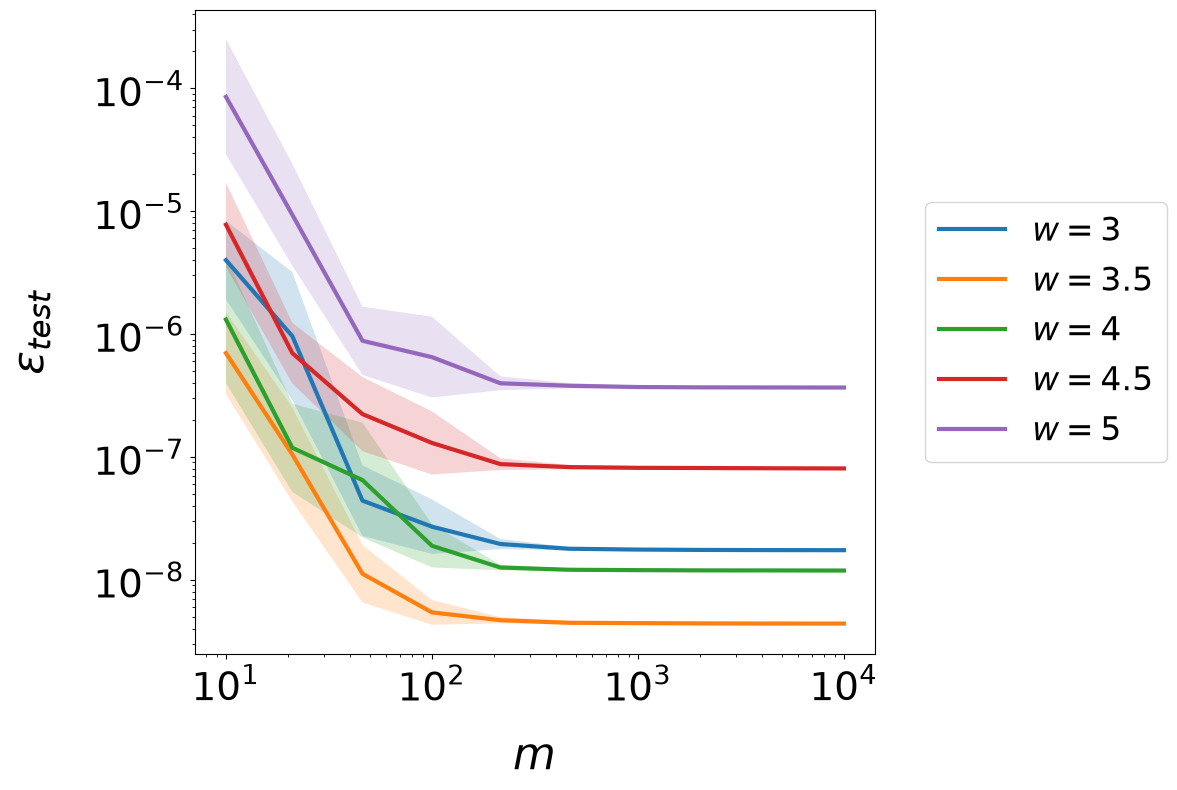

In [32]:

# Plot test error for different bandwidths

plt.figure(figsize=(12, 8))

for ic, c in enumerate(cVal):
    # Mean and relative standard deviation over independent runs
    results_mean = np.mean(MSE_slep[ic], axis=2)
    relative_std = np.std(MSE_slep[ic], axis=2) / results_mean

    plt.loglog(
        Nsamples,
        results_mean[0, :],
        linewidth=3,
        label=fr"$w={c}$"
    )

    plt.fill_between(
        Nsamples,
        results_mean[0, :] / (1 + relative_std[0, :]),
        results_mean[0, :] * (1 + relative_std[0, :]),
        alpha=0.2
    )

plt.xlabel(r"$m$", fontsize=32, labelpad=18)
plt.ylabel(r"$\epsilon_{test}$", fontsize=32, labelpad=28)

plt.tick_params(axis="both", which="major", labelsize=28)
plt.tick_params(axis="both", which="minor", labelsize=28)

plt.legend(
    fontsize=24,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("varying_bandwidth.pdf", bbox_inches="tight")
plt.show()


